LIBRARY

In [409]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

DATA CLEANING

In [410]:
df = pd.read_csv("shopping_trends.csv")
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Venmo,Weekly
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,PayPal,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Venmo,Quarterly
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,PayPal,Express,No,No,24,Venmo,Weekly


In [411]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

In [412]:
df.isnull().sum()

Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

In [413]:
df.duplicated().sum()

0

Exploratory Data Analysis (EDA)

In [414]:
# Group customers into age groups
bins = [0, 18, 30, 50, 65, 100]
labels = ['<18', '18-30', '30-50', '50-65', '65+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases,Age Group
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly,50-65
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly,18-30
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly,30-50
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly,18-30
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually,30-50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Venmo,Weekly,30-50
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,PayPal,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly,50-65
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Venmo,Quarterly,30-50
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,PayPal,Express,No,No,24,Venmo,Weekly,30-50


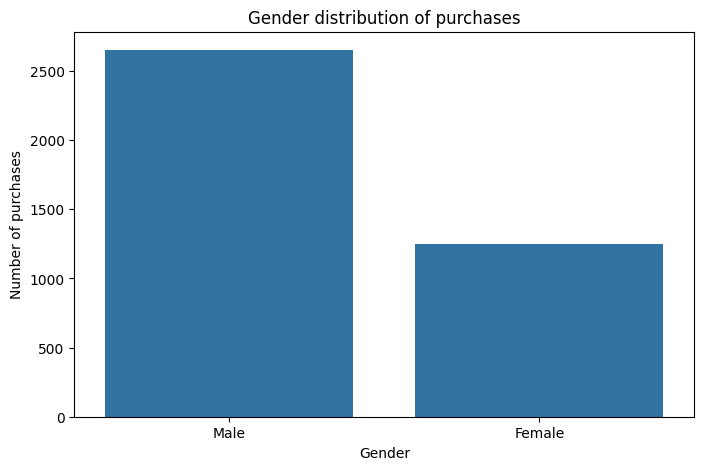

In [415]:
# Analyze purchases by gender
gender_counts = df['Gender'].value_counts()

# Plot gender distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.title('Gender distribution of purchases')
plt.xlabel('Gender')
plt.ylabel('Number of purchases')
plt.show()

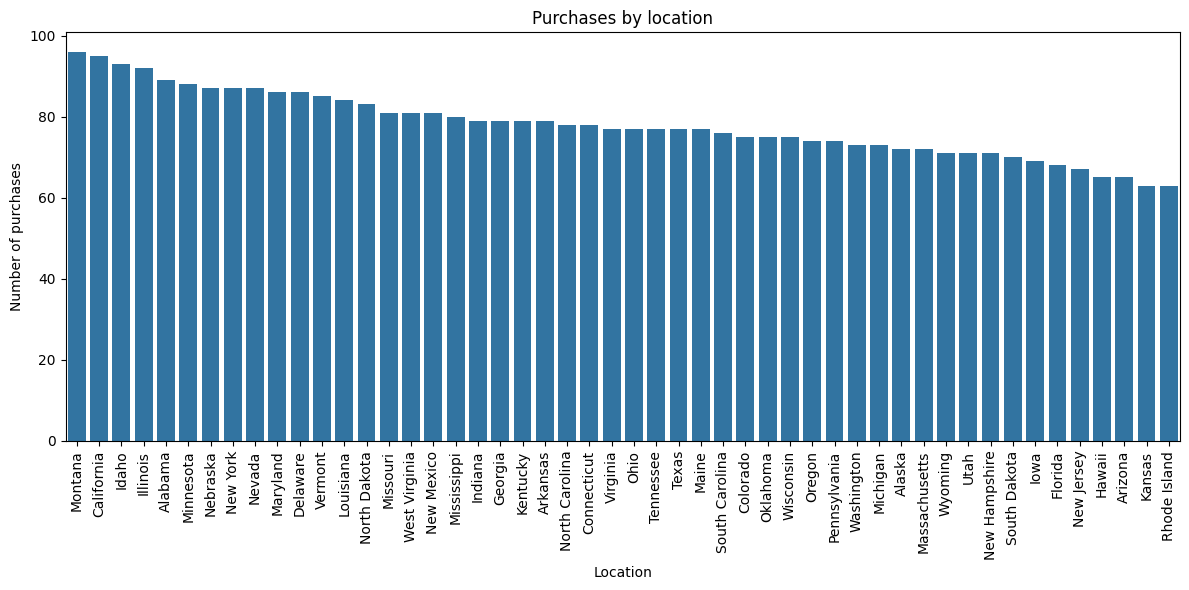

In [416]:
# Analyze purchases by location
location_counts = df['Location'].value_counts()

# Plot purchases by location
plt.figure(figsize=(12, 6))
sns.barplot(x=location_counts.index, y=location_counts.values)
plt.title('Purchases by location')
plt.xlabel('Location')
plt.ylabel('Number of purchases')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [417]:
print(df['Payment Method'].unique())
print(df['Preferred Payment Method'].unique())

['Credit Card' 'Bank Transfer' 'Cash' 'PayPal' 'Venmo' 'Debit Card']
['Venmo' 'Cash' 'Credit Card' 'PayPal' 'Bank Transfer' 'Debit Card']


In [418]:
# Recategorize product & payment method into broader categories
df['Category'] = df['Category'].replace({
    'Blouse': 'Clothing', 'Sweater': 'Clothing', 'Jeans': 'Clothing', 'Hoodie': 'Clothing',
    'Sandals': 'Footwear', 'Shoes': 'Footwear', 'Backpack': 'Accessories',
    'Handbag': 'Accessories', 'Belt': 'Accessories'
})

df['Payment Method'] = df['Payment Method'].replace({
    'Venmo' : 'Digital', 'PayPal' : 'Digital'
})

df['Preferred Payment Method'] = df['Preferred Payment Method'].replace({
    'Venmo' : 'Digital', 'PayPal' : 'Digital'
})

df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases,Age Group
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Digital,Fortnightly,50-65
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly,18-30
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly,30-50
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Digital,Next Day Air,Yes,Yes,49,Digital,Weekly,18-30
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,Digital,Annually,30-50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Digital,Weekly,30-50
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,Digital,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly,50-65
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Digital,Quarterly,30-50
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,Digital,Express,No,No,24,Digital,Weekly,30-50


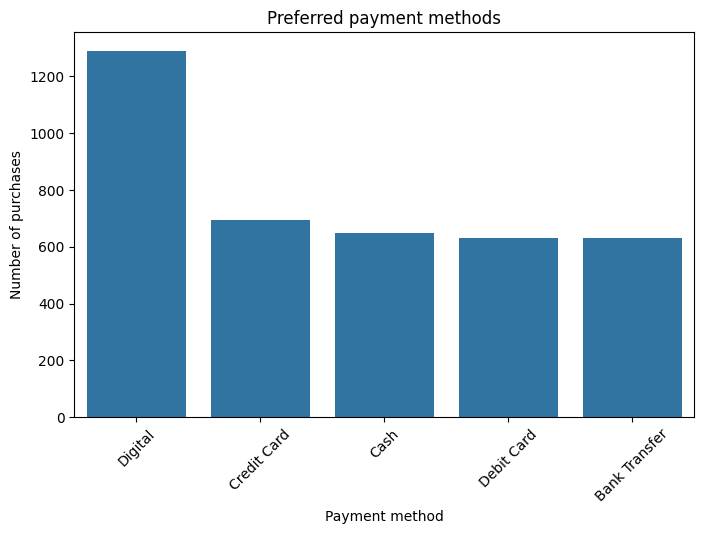

In [419]:
# Analyze payment method preferences
payment_counts = df['Payment Method'].value_counts()

# Plot preferred payment methods
plt.figure(figsize=(8, 5))
sns.barplot(x=payment_counts.index, y=payment_counts.values)
plt.title('Preferred payment methods')
plt.xlabel('Payment method')
plt.ylabel('Number of purchases')
plt.xticks(rotation=45)
plt.show()

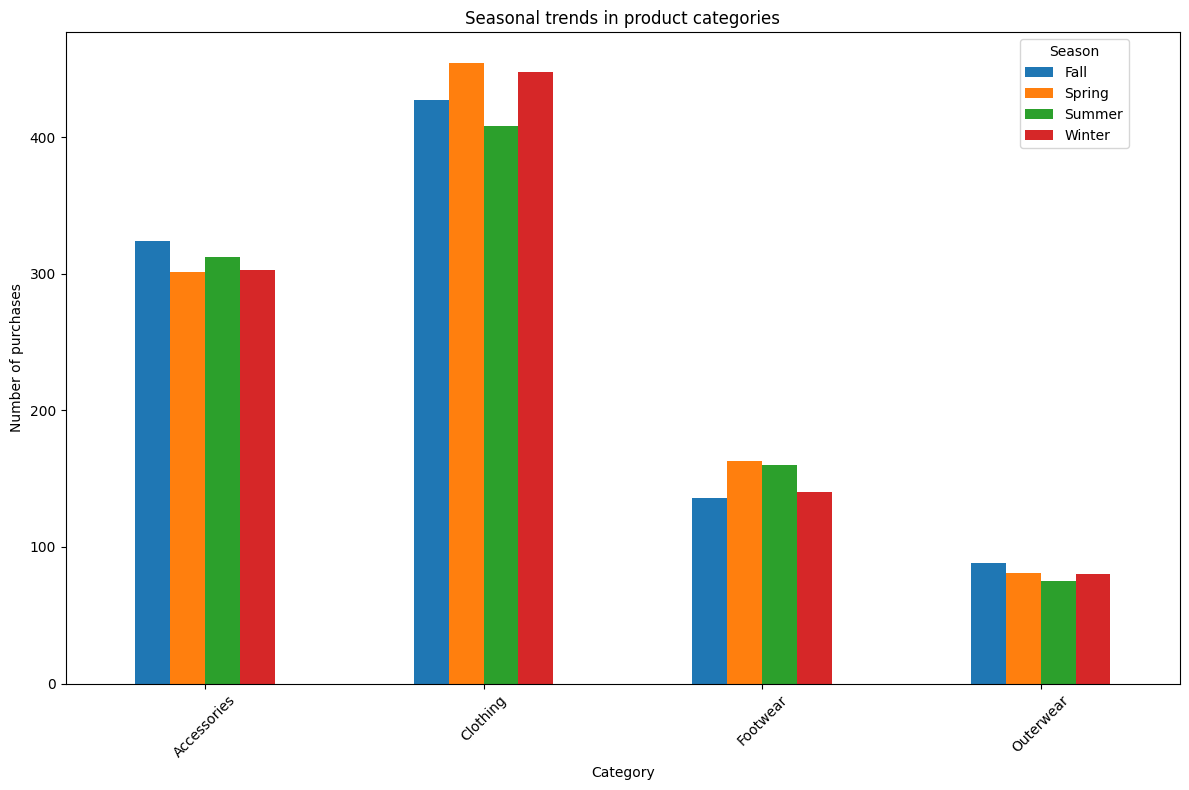

In [420]:
# Group data by category and season
category_season = df.groupby(['Category', 'Season']).size().unstack()

# Plot grouped bar chart for seasonal trends
category_season.plot(kind='bar', figsize=(12, 8))

# Customize the plot
plt.title('Seasonal trends in product categories')
plt.xlabel('Category')
plt.ylabel('Number of purchases')
plt.legend(title='Season', bbox_to_anchor=(0.85, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Correlation Analysis

In [421]:
from sklearn.preprocessing import LabelEncoder

# Label encode binary columns
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])  # Male → 0, Female → 1
df['Discount Applied'] = LabelEncoder().fit_transform(df['Discount Applied'])  # Yes → 1, No → 0
df['Promo Code Used'] = LabelEncoder().fit_transform(df['Promo Code Used'])  # Yes → 1, No → 0

# Map ordinal categories
size_mapping = {'S': 1, 'M': 2, 'L': 3, 'XL' : 4}
df['Size'] = df['Size'].map(size_mapping)

frequency_mapping = {'Weekly': 1, 'Bi-Weekly': 2, 'Monthly': 3, 'Quarterly': 4, 'Annually': 5}
df['Frequency of Purchases'] = df['Frequency of Purchases'].map(frequency_mapping)

# One-hot encode nominal categories
df = pd.get_dummies(df, columns=['Season', 'Payment Method', 'Category', 'Location'], drop_first=True)


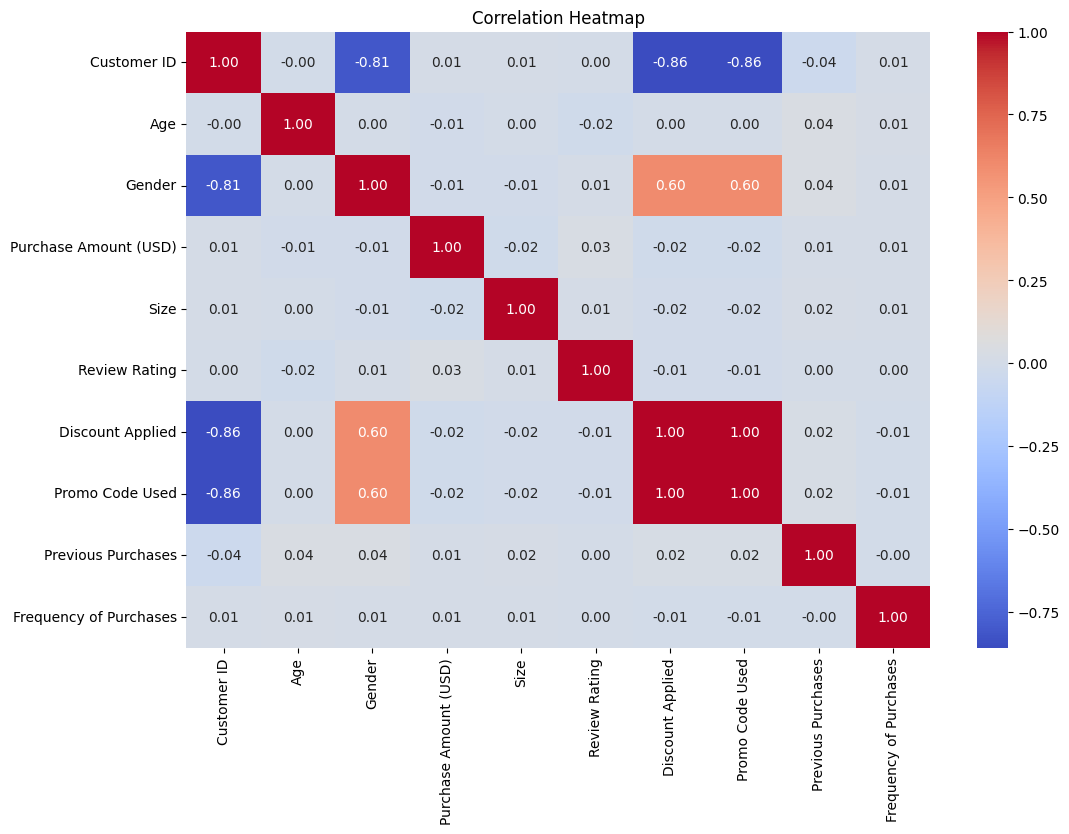

In [422]:
# Select numeric columns only
numeric_cols = df.select_dtypes(include=['float64', 'int64'])

# Calculate correlation matrix
correlation_matrix = numeric_cols.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap')
plt.show()

In [423]:
location_counts

Location
Montana           96
California        95
Idaho             93
Illinois          92
Alabama           89
Minnesota         88
Nebraska          87
New York          87
Nevada            87
Maryland          86
Delaware          86
Vermont           85
Louisiana         84
North Dakota      83
Missouri          81
West Virginia     81
New Mexico        81
Mississippi       80
Indiana           79
Georgia           79
Kentucky          79
Arkansas          79
North Carolina    78
Connecticut       78
Virginia          77
Ohio              77
Tennessee         77
Texas             77
Maine             77
South Carolina    76
Colorado          75
Oklahoma          75
Wisconsin         75
Oregon            74
Pennsylvania      74
Washington        73
Michigan          73
Alaska            72
Massachusetts     72
Wyoming           71
Utah              71
New Hampshire     71
South Dakota      70
Iowa              69
Florida           68
New Jersey        67
Hawaii            65
Ariz

In [424]:
import folium
from folium.plugins import MarkerCluster

states_data = {
    "Montana": 96, "California": 95, "Idaho": 93, "Illinois": 92, "Alabama": 89,
    "Minnesota": 88, "Nebraska": 87, "New York": 87, "Nevada": 87, "Maryland": 86,
    "Delaware": 86, "Vermont": 85, "Louisiana": 84, "North Dakota": 83, "Missouri": 81,
    "West Virginia": 81, "New Mexico": 81, "Mississippi": 80, "Indiana": 79, "Georgia": 79,
    "Kentucky": 79, "Arkansas": 79, "North Carolina": 78, "Connecticut": 78, "Virginia": 77,
    "Ohio": 77, "Tennessee": 77, "Texas": 77, "Maine": 77, "South Carolina": 76,
    "Colorado": 75, "Oklahoma": 75, "Wisconsin": 75, "Oregon": 74, "Pennsylvania": 74,
    "Washington": 73, "Michigan": 73, "Alaska": 72, "Massachusetts": 72, "Wyoming": 71,
    "Utah": 71, "New Hampshire": 71, "South Dakota": 70, "Iowa": 69, "Florida": 68,
    "New Jersey": 67, "Hawaii": 65, "Arizona": 65, "Kansas": 63, "Rhode Island": 63
}

state_to_region = {
    "West": ["Montana", "California", "Idaho", "Nevada", "Colorado", "Utah", "Wyoming", "Alaska", "Hawaii", "Oregon", "Washington", "Arizona"],
    "Midwest": ["Illinois", "Minnesota", "Nebraska", "North Dakota", "Missouri", "Indiana", "Wisconsin", "Iowa", "Kansas", "South Dakota", "Michigan"],
    "South": ["Alabama", "Arkansas", "Delaware", "Florida", "Georgia", "Kentucky", "Louisiana", "Maryland", "Mississippi", "North Carolina", "Oklahoma", "South Carolina", "Tennessee", "Texas", "Virginia", "West Virginia"],
    "Northeast": ["New York", "New Jersey", "Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont", "Pennsylvania"]
}

# Aggregate purchases by region
region_data = {}
for region, states in state_to_region.items():
    region_data[region] = sum(states_data[state] for state in states if state in states_data)

# Approximate center coordinates for each region
region_coordinates = {
    "West": [39.8283, -120.4194],
    "Midwest": [41.8781, -93.0977],
    "South": [32.7765, -96.7969],
    "Northeast": [42.4072, -74.4057]
}

# Create a map centered around the US
map = folium.Map(location=[39.8283, -98.5795], zoom_start=4)

# Add a marker cluster
marker_cluster = MarkerCluster().add_to(map)

# Add regions to the map
for region, purchases in region_data.items():
    folium.CircleMarker(
        location=region_coordinates[region],
        radius=purchases / 20,  # Scale radius based on aggregated purchases
        popup=f"{region}: {purchases} purchases",
        color="red",
        fill=True,
        fill_color="red",
    ).add_to(marker_cluster)

# Save map to HTML file
map.save("aggregated_purchases_by_region.html")

print("Map has been saved as aggregated_purchases_by_region.html. Open it in a browser to view.")


Map has been saved as aggregated_purchases_by_region.html. Open it in a browser to view.


Unsupervised learning

In [425]:
df = pd.read_csv("shopping_trends.csv")

df['Category'] = df['Category'].replace({
    'Blouse': 'Clothing', 'Sweater': 'Clothing', 'Jeans': 'Clothing', 'Hoodie': 'Clothing',
    'Sandals': 'Footwear', 'Shoes': 'Footwear', 'Backpack': 'Accessories',
    'Handbag': 'Accessories', 'Belt': 'Accessories'
})

df['Payment Method'] = df['Payment Method'].replace({
    'Venmo' : 'Digital', 'PayPal' : 'Digital'
})

df['Preferred Payment Method'] = df['Preferred Payment Method'].replace({
    'Venmo' : 'Digital', 'PayPal' : 'Digital'
})

In [426]:
summary = df.groupby('Location').agg(
    Purchases=('Purchase Amount (USD)', 'sum'),
    Male_Percentage=('Gender', lambda x: (x == 'Male').mean() * 100),
    Female_Percentage=('Gender', lambda x: (x == 'Female').mean() * 100),
    Digital_Payments_Percentage=('Payment Method', lambda x: (x == 'Digital').mean() * 100),
    Clothing_Percentage=('Category', lambda x: (x == 'Clothing').mean() * 100),
    Accessories_Percentage=('Category', lambda x: (x == 'Accessories').mean() * 100)
).reset_index()

summary.rename(columns={
    'Male_Percentage': 'Male (%)',
    'Female_Percentage': 'Female (%)',
    'Digital_Payments_Percentage': 'Digital Payments (%)',
    'Clothing_Percentage': 'Clothing (%)',
    'Accessories_Percentage': 'Accessories (%)'
}, inplace=True)


# Display the normalized dataframe
summary.head()

,Location,Purchases,Male (%),Female (%),Digital Payments (%),Clothing (%),Accessories (%)
0,Alabama,5261,69.662921,30.337079,34.831461,46.067416,28.089888
1,Alaska,4867,66.666667,33.333333,30.555556,45.833333,36.111111
2,Arizona,4326,61.538462,38.461538,29.230769,49.230769,30.769231
3,Arkansas,4828,68.354430,31.645570,32.911392,46.835443,32.911392
4,California,5605,69.473684,30.526316,30.526316,49.473684,32.631579


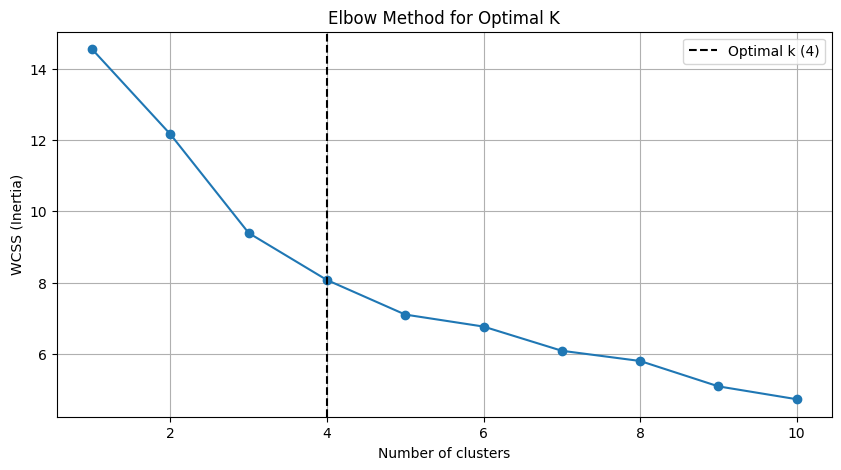

In [427]:
from sklearn.cluster import KMeans
from kneed import KneeLocator 
from sklearn.preprocessing import MinMaxScaler

# Prepare data for clustering
features = ["Purchases", "Male (%)", "Female (%)", "Digital Payments (%)", "Clothing (%)", "Accessories (%)"]
X = summary[features]

# Normalize the data
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(X)

# Determine the optimal number of clusters using the Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

# Use KneeLocator to find the optimal K
knee_locator = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")
optimal_k = knee_locator.knee

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.axvline(x=optimal_k, color='black', linestyle='--', label=f"Optimal k ({optimal_k})")
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.legend()
plt.show()

In [428]:
# Perform K-Means clustering with the optimal K
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)
summary['Cluster'] = kmeans.fit_predict(scaled_features)

In [429]:
cluster_0 = summary[summary["Cluster"] == 0]["Location"].reset_index(drop=True)
cluster_1 = summary[summary["Cluster"] == 1]["Location"].reset_index(drop=True)
cluster_2 = summary[summary["Cluster"] == 2]["Location"].reset_index(drop=True)
cluster_3 = summary[summary["Cluster"] == 3]["Location"].reset_index(drop=True)

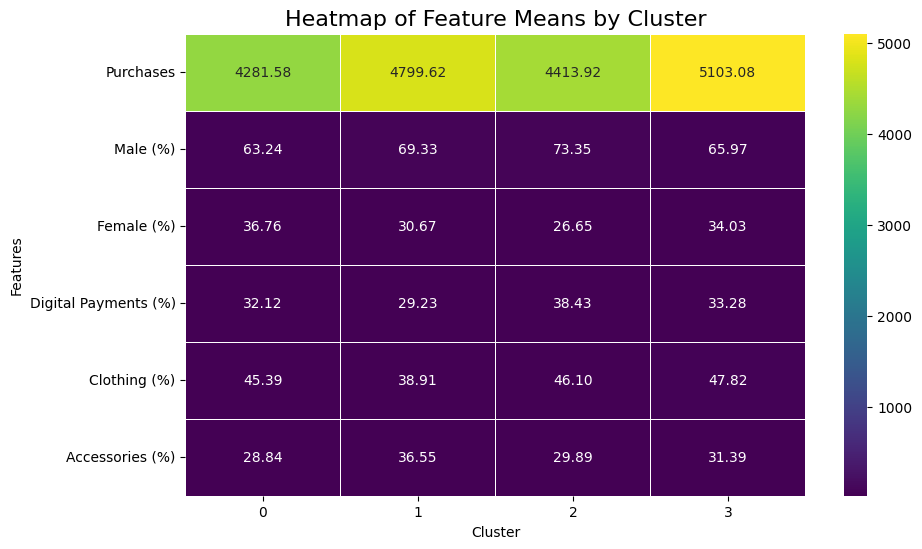

In [431]:
import seaborn as sns

cluster_means = summary.groupby('Cluster')[["Purchases", "Male (%)", "Female (%)", "Digital Payments (%)", "Clothing (%)", "Accessories (%)"]].mean()

plt.figure(figsize=(10, 6))
sns.heatmap(cluster_means.T, cmap="viridis", annot=True, fmt=".2f", linewidths=0.5)
plt.title('Heatmap of Feature Means by Cluster', size=16)
plt.xlabel('Cluster')
plt.ylabel('Features')
plt.show()

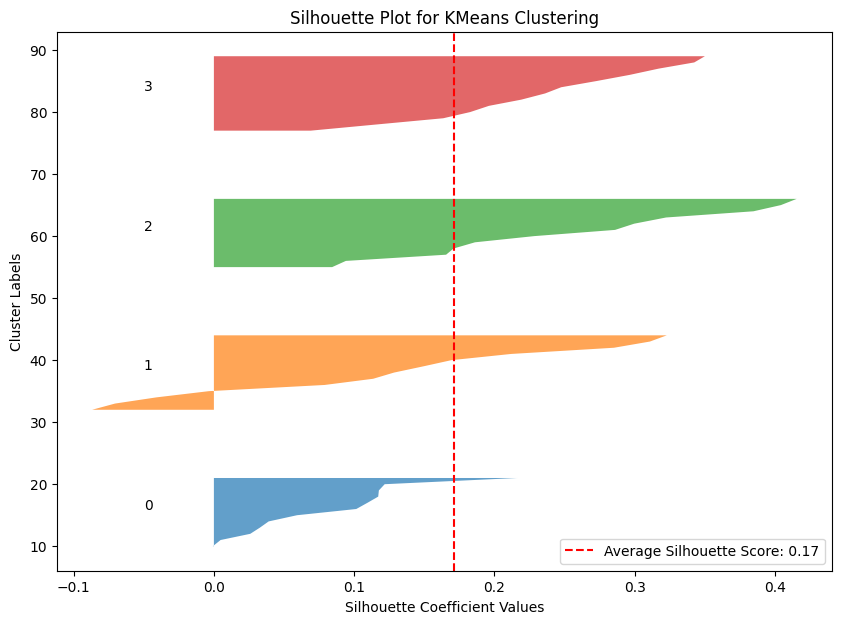

In [432]:
from sklearn.metrics import silhouette_samples, silhouette_score
import numpy as np

# Calculate silhouette scores for each sample
silhouette_avg = silhouette_score(scaled_features, summary['Cluster'])
sample_silhouette_values = silhouette_samples(scaled_features, summary['Cluster'])

# Plot silhouette scores
plt.figure(figsize=(10, 7))
y_lower = 10
n_clusters = optimal_k

for i in range(n_clusters):
    ith_cluster_silhouette_values = sample_silhouette_values[summary['Cluster'] == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0, ith_cluster_silhouette_values,
        alpha=0.7
    )

    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

plt.axvline(x=silhouette_avg, color="red", linestyle="--", label=f"Average Silhouette Score: {silhouette_avg:.2f}")
plt.title("Silhouette Plot for KMeans Clustering")
plt.xlabel("Silhouette Coefficient Values")
plt.ylabel("Cluster Labels")
plt.legend()
plt.show()

Classification Task

In [433]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, RobustScaler, OrdinalEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, auc
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_csv("shopping_trends.csv")

# **Tambahkan fitur yang lebih relevan**
selected_columns = [
    "Gender", "Discount Applied", "Promo Code Used", "Payment Method", 
    "Frequency of Purchases", "Season", "Review Rating", "Previous Purchases", "Size", "Purchase Amount (USD)"
]
df_class = df[selected_columns].copy()

# Label encode binary categorical columns
binary_cols = ["Gender", "Discount Applied", "Promo Code Used"]
for col in binary_cols:
    le = LabelEncoder()
    df_class[col] = le.fit_transform(df_class[col])

# **Gunakan Ordinal Encoding untuk fitur dengan banyak kategori**
ordinal_encoder = OrdinalEncoder()
df_class[["Payment Method", "Frequency of Purchases", "Season"]] = ordinal_encoder.fit_transform(
    df_class[["Payment Method", "Frequency of Purchases", "Season"]])

# Ubah 'Size' menjadi numerik
size_mapping = {"S": 1, "M": 2, "L": 3, "XL": 4}
df_class["Size"] = df_class["Size"].map(size_mapping)

# **Tambahkan fitur interaksi tambahan**
df_class["Promo_Discount_Interaction"] = df_class["Promo Code Used"] * df_class["Discount Applied"]
df_class["Previous_Promo_Interaction"] = df_class["Promo Code Used"] * df_class["Previous Purchases"]
df_class["Avg_Purchase_Amount"] = df_class["Purchase Amount (USD)"] / (df_class["Previous Purchases"] + 1)

# Define features and target variable
X = df_class.drop(columns=["Purchase Amount (USD)"])  
y = df_class["Purchase Amount (USD)"].apply(lambda x: 1 if x > df_class["Purchase Amount (USD)"].median() else 0)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# **Gunakan RobustScaler untuk menangani outlier**
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **Hyperparameter tuning untuk beberapa model utama**
rf_params = {"n_estimators": [200, 500], "max_depth": [10, 20], "min_samples_split": [2, 5]}
xgb_params = {"n_estimators": [200, 500], "max_depth": [8, 12], "learning_rate": [0.01, 0.05]}

# **Train classifiers dengan parameter yang lebih optimal**
models = {
    "Random Forest": GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=3, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=500, learning_rate=0.02, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, weights="distance"),
    "SVM": SVC(probability=True, kernel="linear", C=1.5, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, min_samples_split=4, random_state=42)
}

# Train and evaluate models
results = []
for name, model in models.items():
    if isinstance(model, GridSearchCV):
        model.fit(X_train, y_train)
        best_model = model.best_estimator_
        y_pred = best_model.predict(X_test)
        y_prob = best_model.predict_proba(X_test)[:, 1]
    elif name in ["Logistic Regression", "SVM", "K-Nearest Neighbors", "LDA"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    results.append([name, accuracy, auc_score])

# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "AUC"]).sort_values(by="Accuracy", ascending=False)
results_df

,Model,Accuracy,AUC
4,Decision Tree,0.988462,0.988514
0,Random Forest,0.952564,0.993466
1,AdaBoost,0.834615,0.958067
2,K-Nearest Neighbors,0.721795,0.790728
3,SVM,0.702564,0.783842


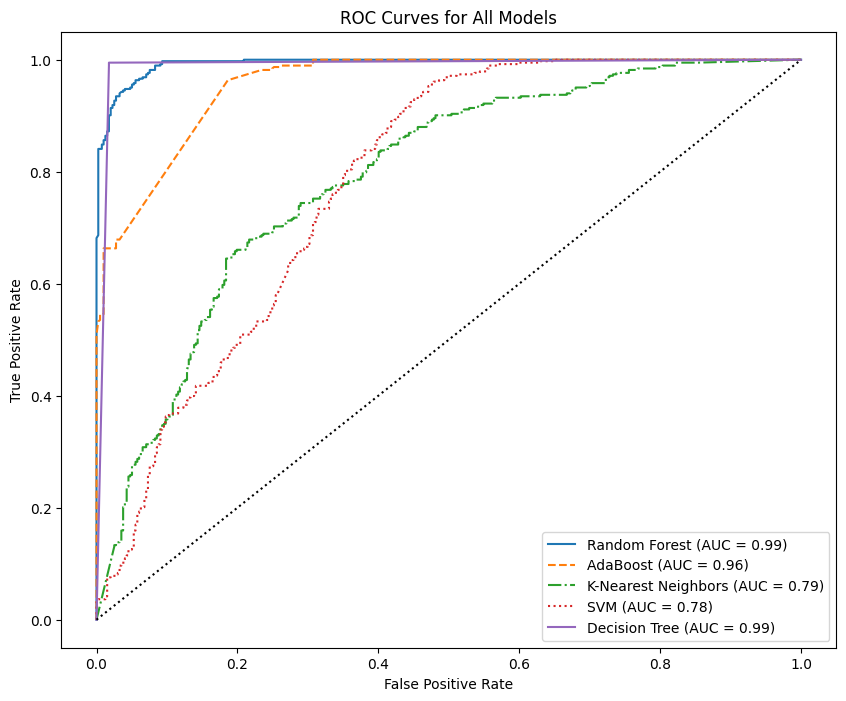

In [434]:
# Plot ROC curves for all models
plt.figure(figsize=(10, 8))

# Define line styles for different models
line_styles = ["solid", "dashed", "dashdot", "dotted"]

for idx, (name, model) in enumerate(models.items()):
    if name in ["SVM", "K-Nearest Neighbors"]:
        y_score = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_score = model.predict_proba(X_test)[:, 1]

    # Compute ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    # Plot ROC Curve
    plt.plot(fpr, tpr, linestyle=line_styles[idx % len(line_styles)], label=f"{name} (AUC = {roc_auc:.2f})")

# Diagonal reference line
plt.plot([0, 1], [0, 1], linestyle=":", color="black")

# Labels and title
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All Models")
plt.legend(loc="lower right")

# Show the plot
plt.show()


Regression Task

In [435]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, PowerTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("shopping_trends.csv")

# Select relevant features for regression
selected_columns = [
    "Gender", "Discount Applied", "Promo Code Used", "Payment Method",
    "Frequency of Purchases", "Season", "Review Rating", "Previous Purchases", "Size", "Purchase Amount (USD)"
]
df_reg = df[selected_columns].copy()

# Label encode categorical features
categorical_columns = ["Gender", "Discount Applied", "Promo Code Used", "Payment Method", "Frequency of Purchases", "Season"]
for col in categorical_columns:
    le = LabelEncoder()
    df_reg[col] = le.fit_transform(df_reg[col])

# Transform 'Size' into numerical values
size_mapping = {"S": 1, "M": 2, "L": 3, "XL": 4}
df_reg["Size"] = df_reg["Size"].map(size_mapping)

# Feature Engineering: Add new interaction features
df_reg["Promo_Discount_Interaction"] = df_reg["Promo Code Used"] * df_reg["Discount Applied"]
df_reg["Previous_Promo_Interaction"] = df_reg["Promo Code Used"] * df_reg["Previous Purchases"]
df_reg["Avg_Purchase_Amount"] = df_reg["Purchase Amount (USD)"] / (df_reg["Previous Purchases"] + 1)

# Define features and target variable
X = df_reg.drop(columns=["Purchase Amount (USD)"])  # Features
y = df_reg["Purchase Amount (USD)"]  # Target (continuous variable)

# Apply power transformation to stabilize target variable distribution
power_transformer = PowerTransformer(method='yeo-johnson')
y_transformed = power_transformer.fit_transform(y.values.reshape(-1, 1)).flatten()

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_transformed, test_size=0.2, random_state=42)

# Apply standardization for selected models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define regression models
regressors = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=200, learning_rate=0.05, random_state=42),
    "SVM": SVR(kernel="rbf"),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
}

# Train and evaluate models
results = []
for name, model in regressors.items():
    if name in ["Linear Regression", "SVM", "Ridge Regression", "Lasso Regression", "ElasticNet"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results.append([name, mae, rmse, r2])

# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'MAE', 'RMSE', 'R²']).sort_values(by='R²', ascending=False)
results_df


,Model,MAE,RMSE,R²
1,Random Forest,0.031237,0.042926,0.998162
4,Decision Tree,0.093193,0.137494,0.981140
3,SVM,0.272545,0.379645,0.856210
2,AdaBoost,0.472281,0.584585,0.659067
0,Linear Regression,0.805154,0.934771,0.128267


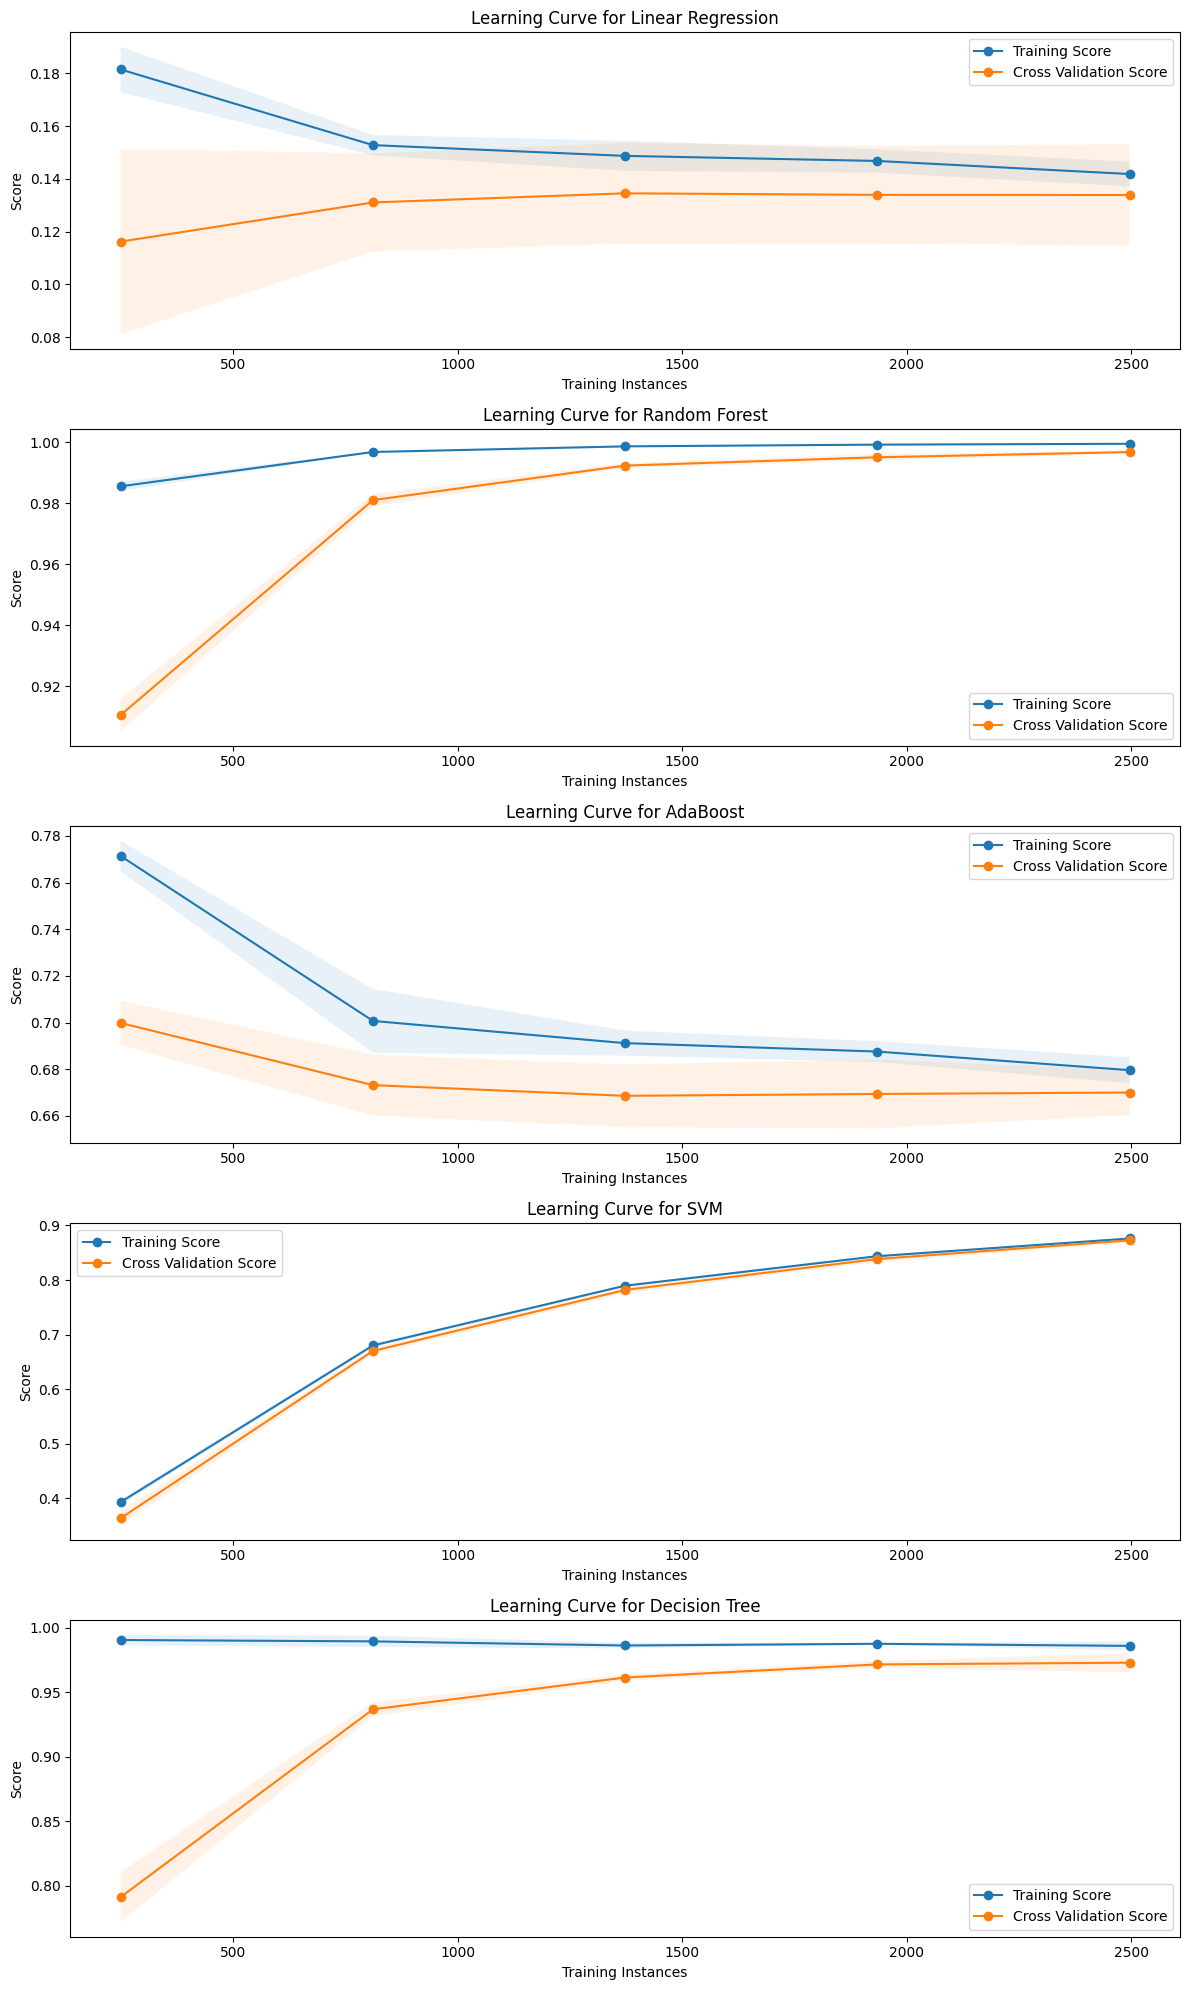

In [440]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(5, 1, figsize=(12, 30))

for idx, (name, model) in enumerate(regressors.items()):
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train, y_train, cv=5, scoring="r2", train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1
    )

    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)

    axes[idx].plot(train_sizes, train_scores_mean, 'o-', label="Training Score")
    axes[idx].plot(train_sizes, test_scores_mean, 'o-', label="Cross Validation Score")
    axes[idx].fill_between(train_sizes, train_scores_mean - train_scores.std(axis=1), 
                           train_scores_mean + train_scores.std(axis=1), alpha=0.1)
    axes[idx].fill_between(train_sizes, test_scores_mean - test_scores.std(axis=1), 
                           test_scores_mean + test_scores.std(axis=1), alpha=0.1)

    axes[idx].set_xlabel("Training Instances")
    axes[idx].set_ylabel("Score")
    axes[idx].set_title(f"Learning Curve for {name}")
    axes[idx].legend(loc="best")

plt.tight_layout()
plt.show()
